### ORIENTATION ANALYSIS FOR STABILITY TESTS 

Goals: 
1. plot RMSD for hydrogen and oxygen separately 
2. Look at orientation changes of hydrogen in stability tests 

In [1]:
import signac 
import freud 
import hoomd 
import gsd.hoomd
import os

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["axes.titlepad"] = 20
import rowan  # for quaternion math, see rowan.readthedocs.io for more information.
from mpl_toolkits.mplot3d import Axes3D



In [26]:
# initialize project 

project = signac.init_project("/home/clarivi/projects/IceCrystal_Project/data/data/")

jobs = [job.id for job in project.find_jobs({"compression":False, "crystal_name": "141_H2O_0", "seed":2})]
print(jobs)

['6f50fbdfe1a4dfbd7ccb705bb66494bf']


### Relative Orientation Analysis: 

Using freud relative orientation to understand how the hydrogen particle orientation is changing over the course of the simulation

BRAINSTORMING: 
- I need to find the equivalent orientations of my shapes in order to use this algorithm -- how to find the symmetry 
- Q: does the point set used to generate the shape necessarily have the same symmetry as the shape itself?  

In [3]:
#for every stability test job 
for job in project.find_jobs({"compression": False}):
    if os.path.isfile(job.fn("trajectory.gsd")):
            data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
    else: 
        data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')
    ## Find equivalent orientations for shape: 
    

    ref_box, ref_points = data[0].configuration.box, data[0].particles.position
    ref_orientations = data[0].particles.orientation

    avg_angular_sep = np.zeros(len(data))

    for frame in range(len(data)):
        box, points = data[frame].configuration.box, data[frame].particles.position
        orientations = data[frame].particles.orientation



### Mean squared relative displacement 

- identify 2 nearest oxygen neighbors of each hydrogen 
- calculate mean square displacement of all 3 particles, take the difference? 
- might actually be easier to do as pairs? 

calculate per particle mean squared displacement, then take difference between that for pairs of oxygen, hydrogen 


0acb90d2fc1f7ee6a91f3557e2a55c2c
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2671, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2672, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2670, 2)
(2670, 2)
(2671, 2)
(2670, 2)
(2670, 2)
(2670, 2)
(2671, 2)
(2670, 2)
(2670, 2)
(2671, 2)
(2670, 2)
(2670, 2)
(2670, 2)
(2670, 2)
(2671, 2)
(2669, 2)
(2670, 2)
(2670, 2)
(2670, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2671, 2)
(2672, 2)
(2672, 2)
(2670, 2)
(2670, 2)
(2670, 2)
(2669, 2)
(2671, 2)
(2670, 2)
(2671, 2)
(2669, 2)
(2670, 2)
(2669, 2)
(2670, 2)
(2669, 2)
(2669, 2)
(2670, 2)
(2669, 2)
(2669, 2)
(2670, 2)
(2668, 2)
(2669, 

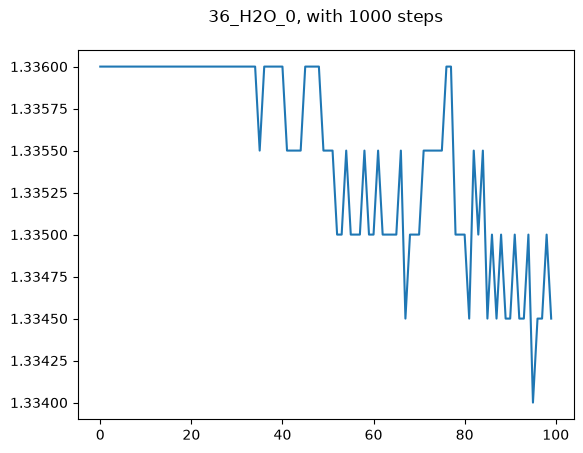

8a72d0a994be84219d94b962255ec93f
(3767, 2)
(3660, 2)
(3600, 2)
(3559, 2)
(3459, 2)
(3414, 2)
(3388, 2)
(3306, 2)
(3287, 2)
(3199, 2)
(3197, 2)
(3186, 2)
(3140, 2)
(3115, 2)
(3084, 2)
(3031, 2)
(3018, 2)
(2970, 2)
(2901, 2)
(2897, 2)
(2877, 2)
(2817, 2)
(2825, 2)
(2763, 2)
(2740, 2)
(2680, 2)
(2681, 2)
(2622, 2)
(2618, 2)
(2561, 2)
(2560, 2)
(2540, 2)
(2480, 2)
(2469, 2)
(2447, 2)


In [ ]:
# find all oxygen nearest neighbors of hydrogen particles: 2 nearest neighbors of type oxygen using freud 

for job in project.find_jobs({"compression": False}):
    print(job.id)
    if os.path.isfile(job.fn("trajectory.gsd")):
        data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
    else: 
        data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')

    plot_points = 100
    oxygen_neighbors = np.zeros(plot_points)

    for frame in range(plot_points):
        data_frame = int(frame * len(data)/plot_points)
        box, points = data[data_frame].configuration.box, data[data_frame].particles.position

        aq = freud.locality.AABBQuery(box, points)

        #query points are only hydrogen atoms 
        query_ids = np.where(data[data_frame].particles.typeid == 1)

        query_points = data[data_frame].particles.position[query_ids]

        distances = []

        #find 2 nearest neighbors - in perfect crystal, these should both be oxygen particles
        query_result = aq.query(query_points, dict(num_neighbors=4, exclude_ii=True))

        nlist = query_result.toNeighborList()

        # find average number of hydrogen nearest neighbors which are oxygen: 
        oxygen_neighbor_list = np.zeros(len(query_points))
        hydrogen_neighbor_list = np.zeros(len(query_points))
        
        HO_pair_list = [[i, j] for i, j in nlist if [data[data_frame].particles.typeid[i], data[data_frame].particles.typeid[j]] == [1, 0]]
        
        for i, j in HO_pair_list:
            oxygen_neighbor_list[i] += 1 
        

        oxygen_neighbors[frame] = np.average(oxygen_neighbor_list)

    plt.plot(oxygen_neighbors)
    plt.title(f"{job.sp.crystal_name}, with {job.sp.runtime} steps")
    plt.show()
  
        
        

0acb90d2fc1f7ee6a91f3557e2a55c2c


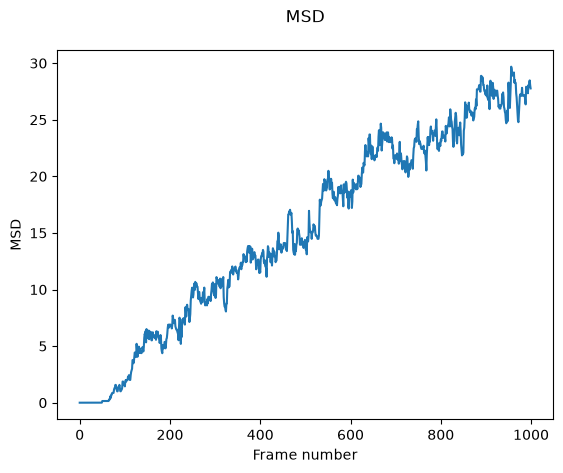

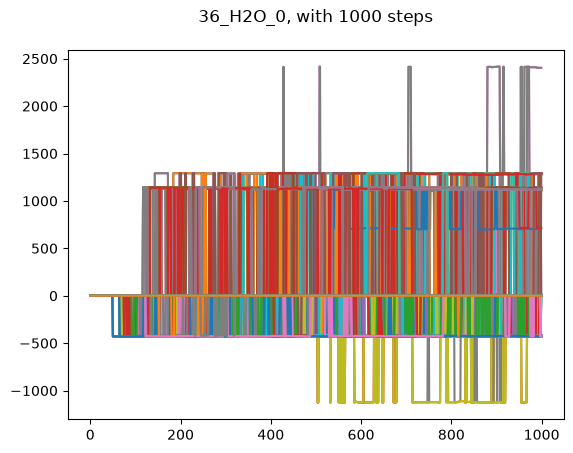

8a72d0a994be84219d94b962255ec93f


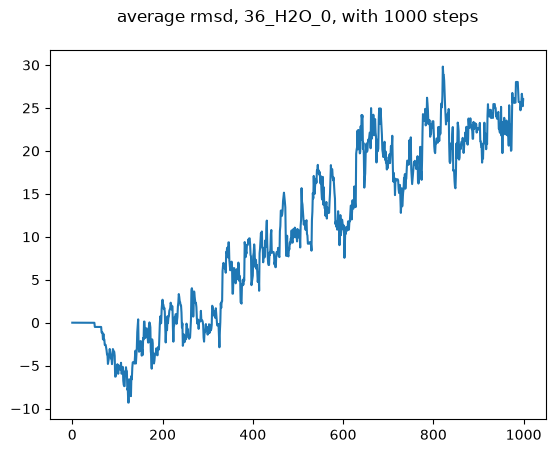

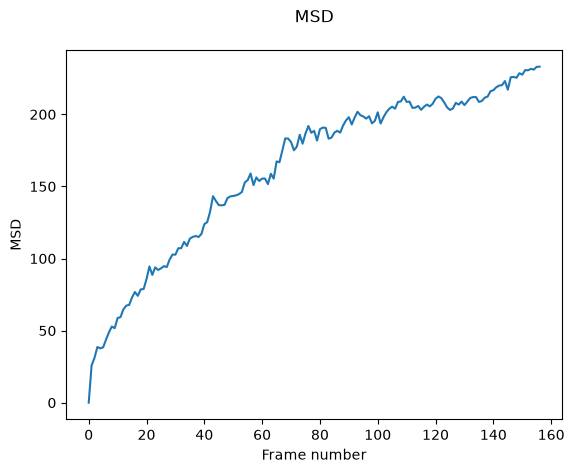

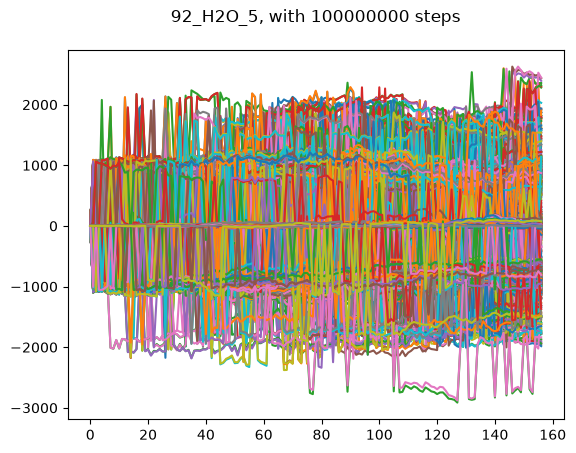

65103e4c39a1a5611a990dc9b2ffaebd


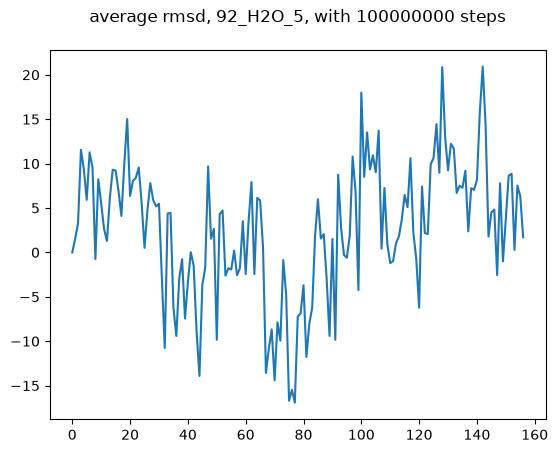

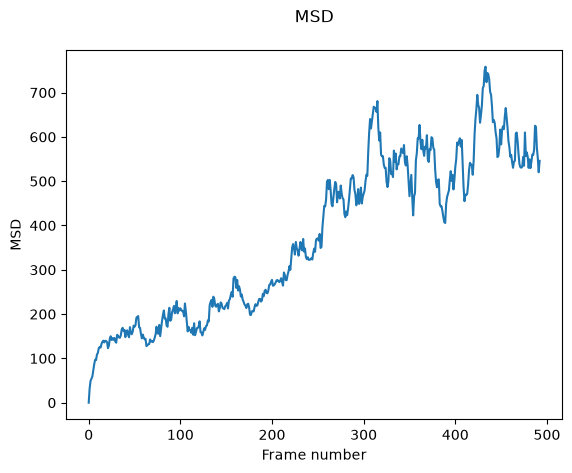

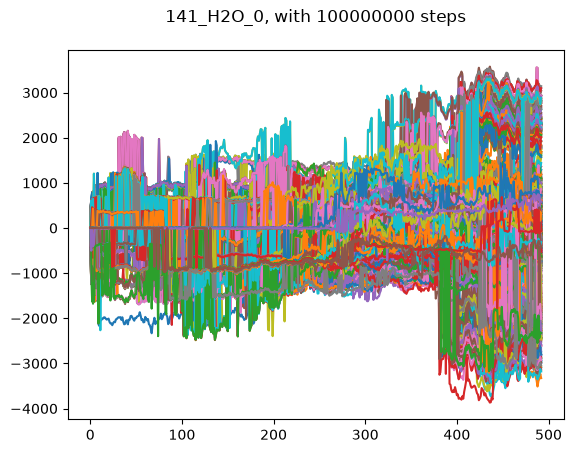

a5dca1510d16bd9c9dac578089a7572e


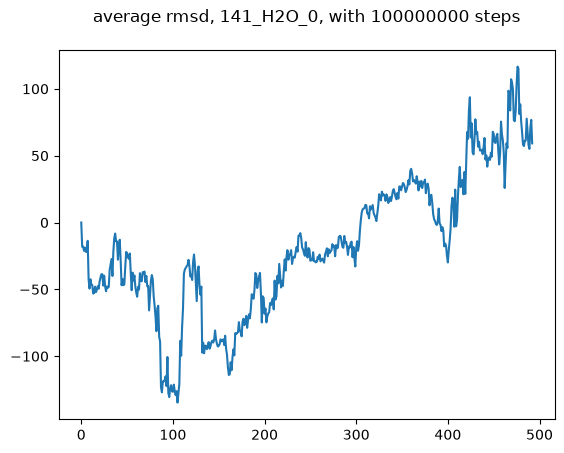

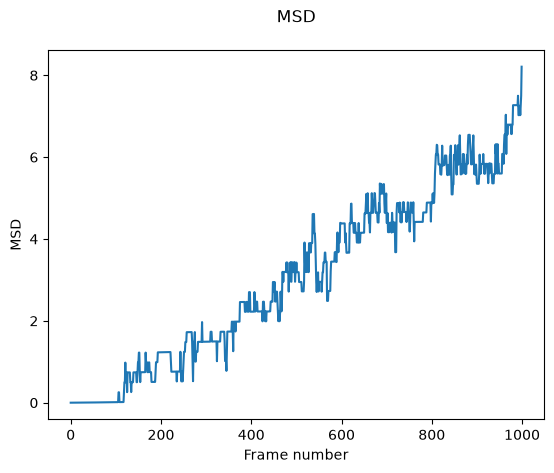

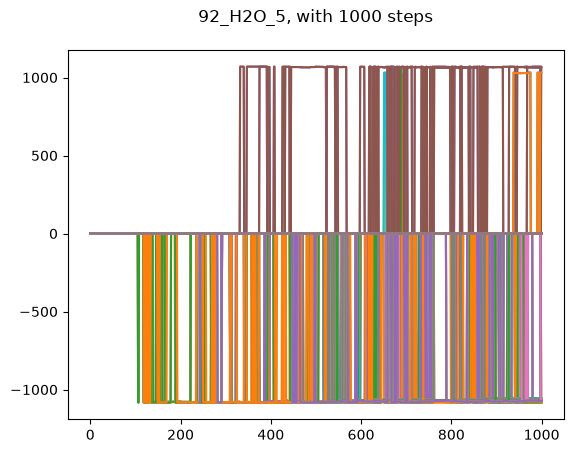

f81c244c5c3f88b8f7adb5f194b9c020


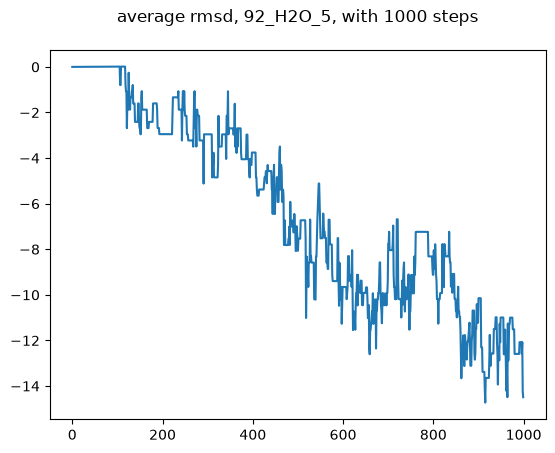

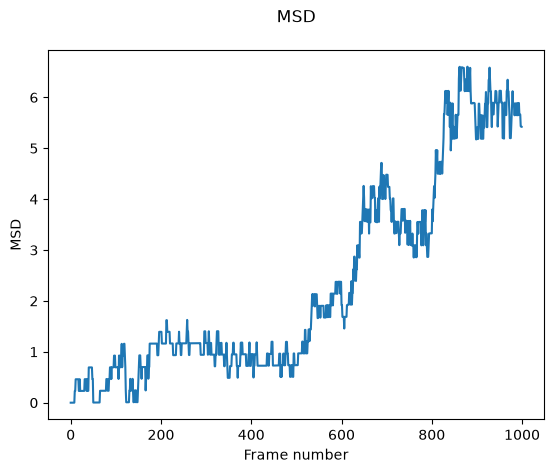

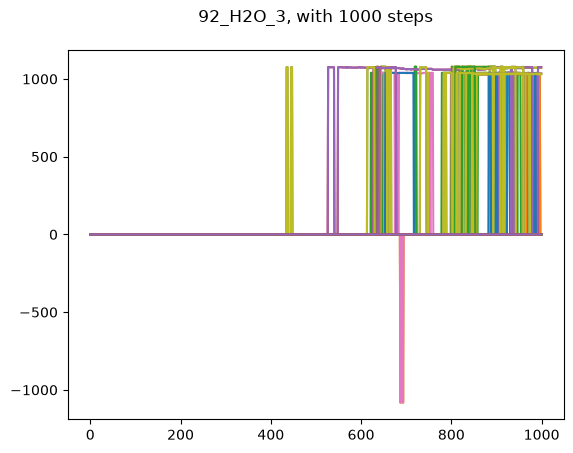

cfc45f318d66ca725eeeccdbfdc27e38


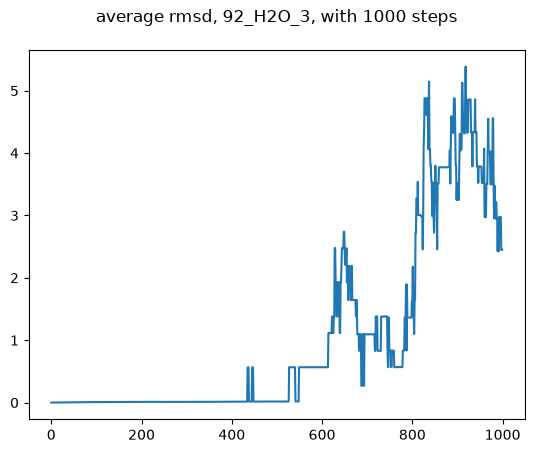

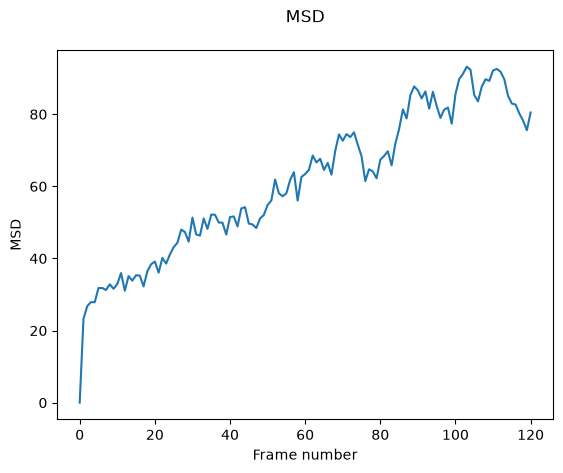

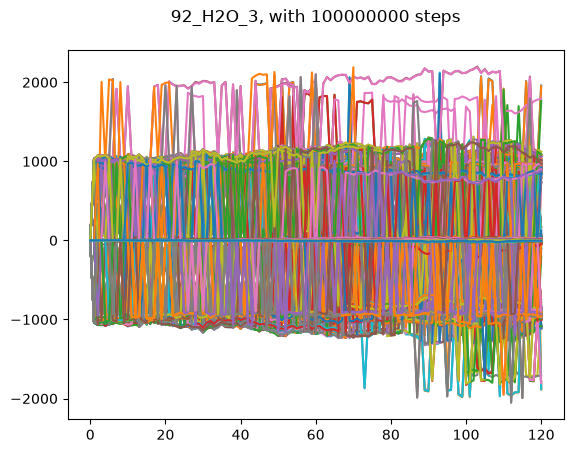

8c4170775af752b4bcba71fa68170e40


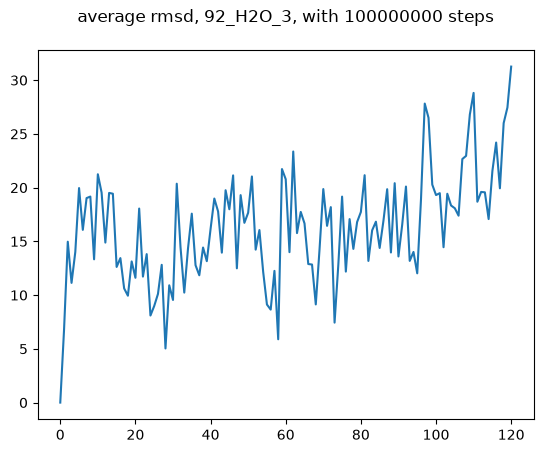

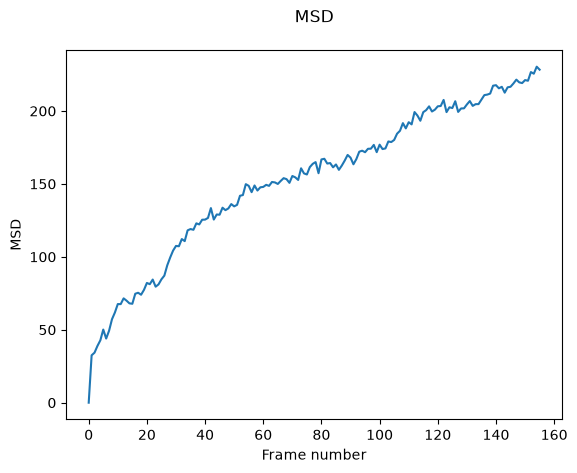

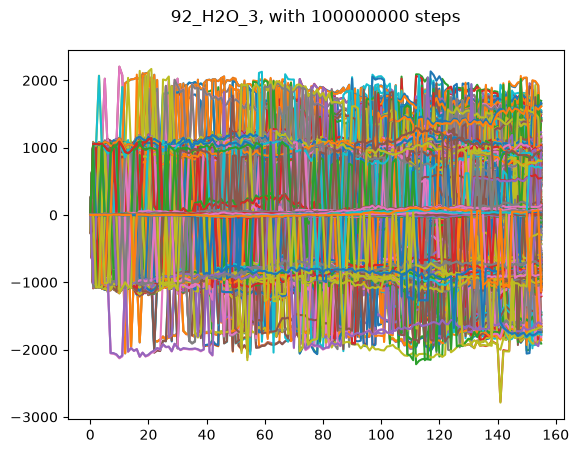

8933ba88e6097c4ac8b824b1cb8a0e34


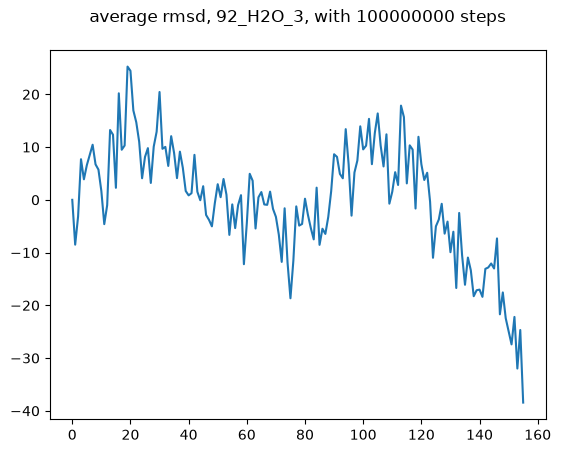

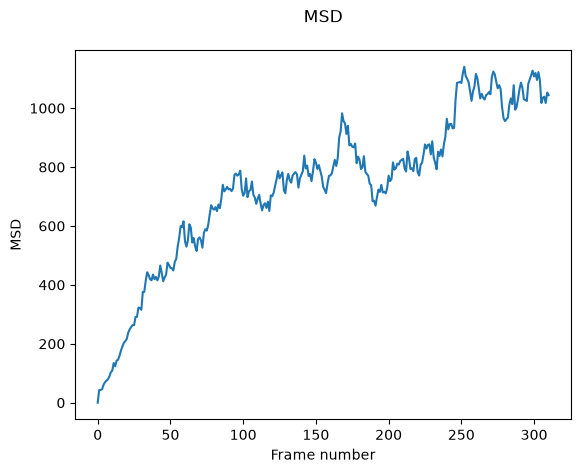

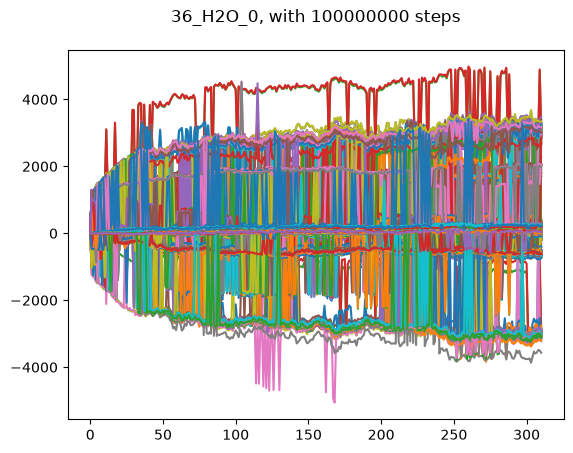

6f0bf87d03519e889d454294a9d192c4


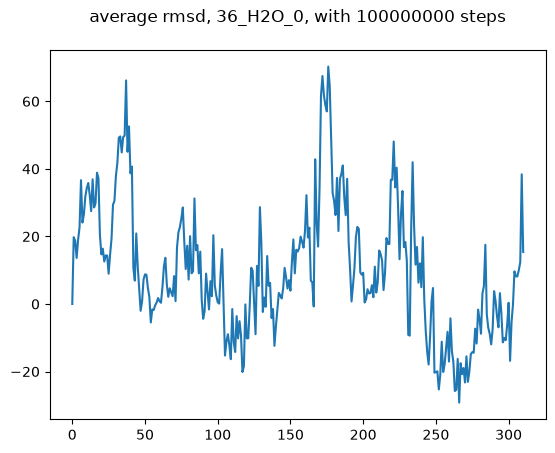

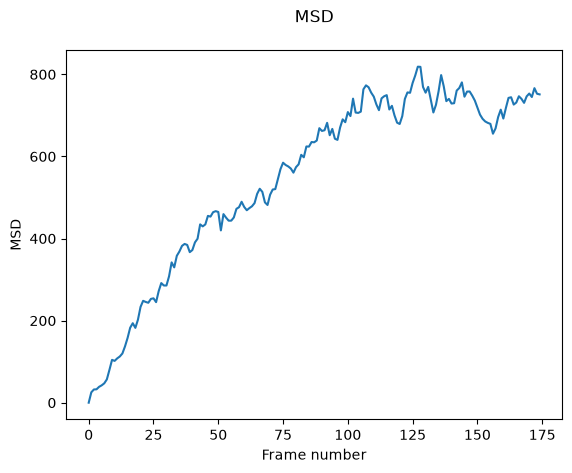

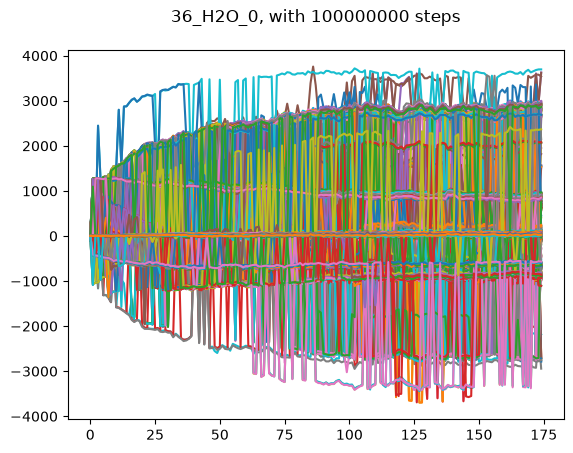

a1969d8535a15682c46ff2512be08a16


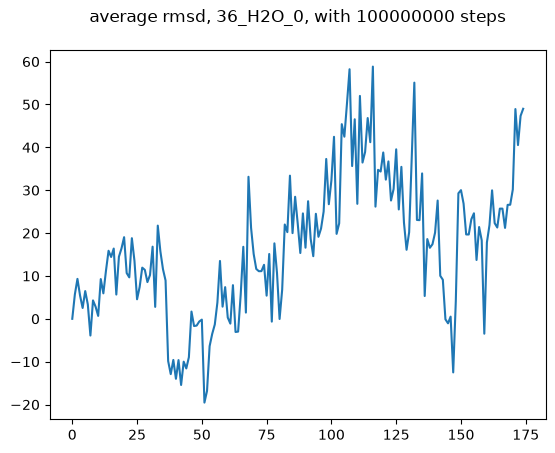

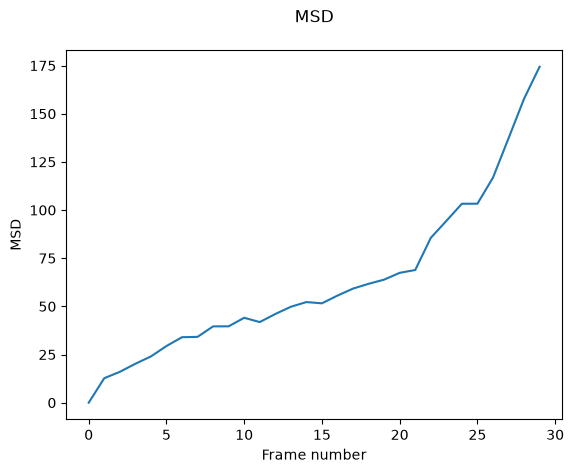

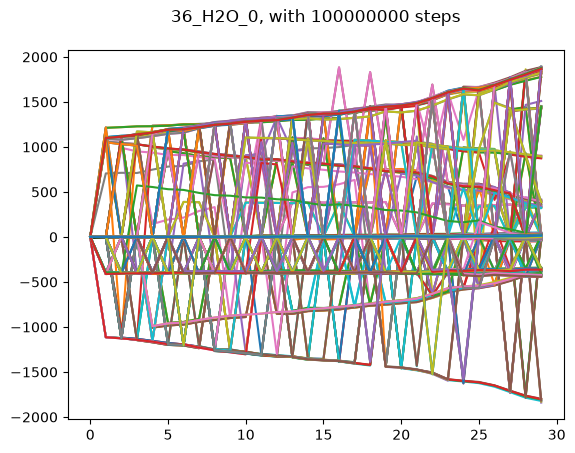

ca37ea22523f307172e9948e444989f9


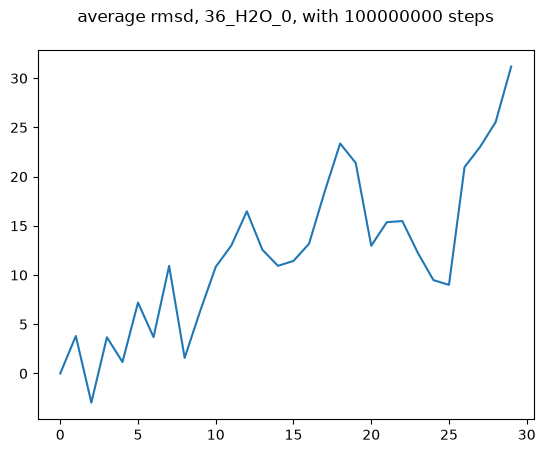

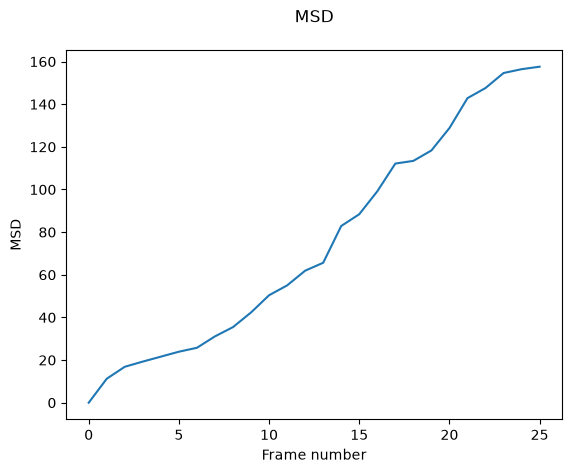

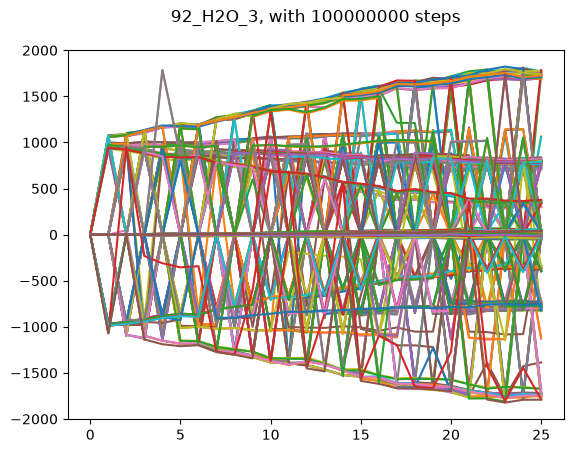

f46e833987cc9d4065398258dbf1b24f


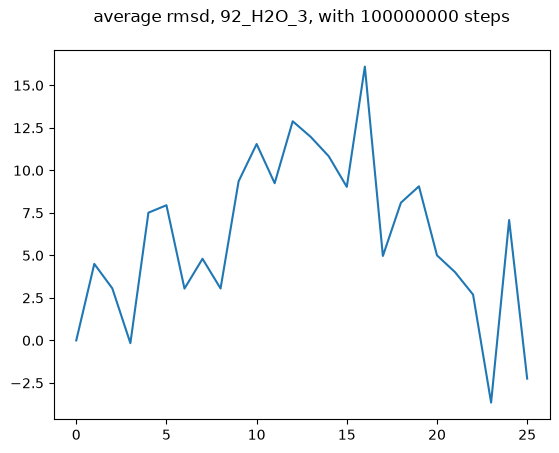

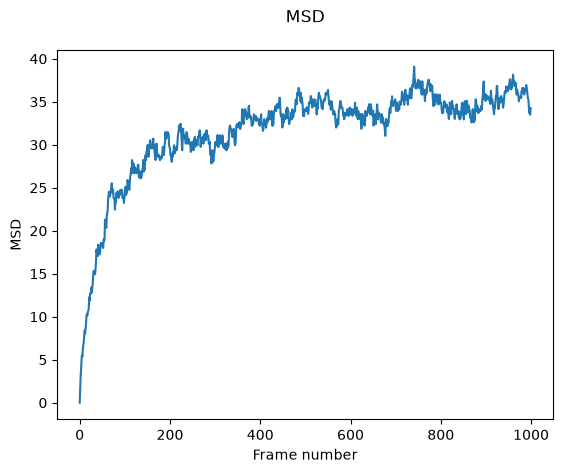

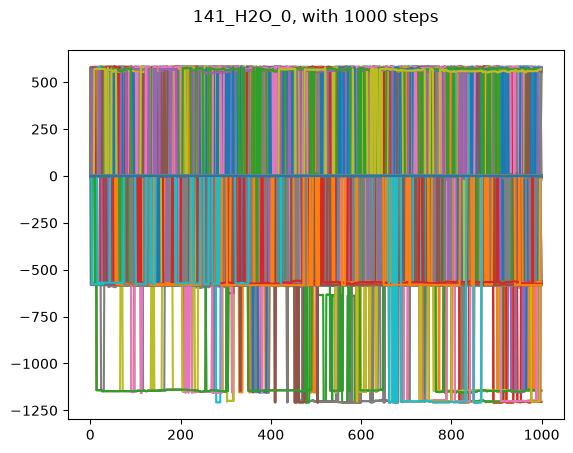

6f50fbdfe1a4dfbd7ccb705bb66494bf


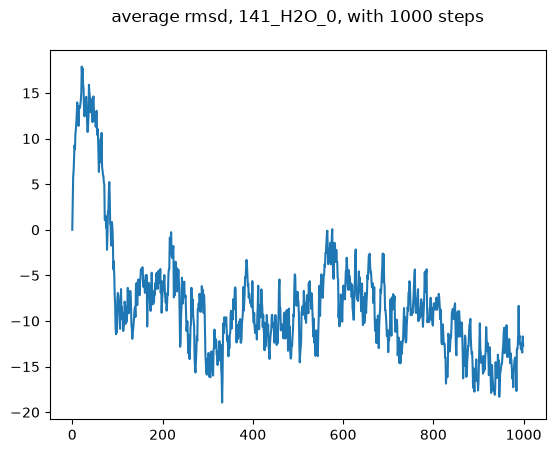

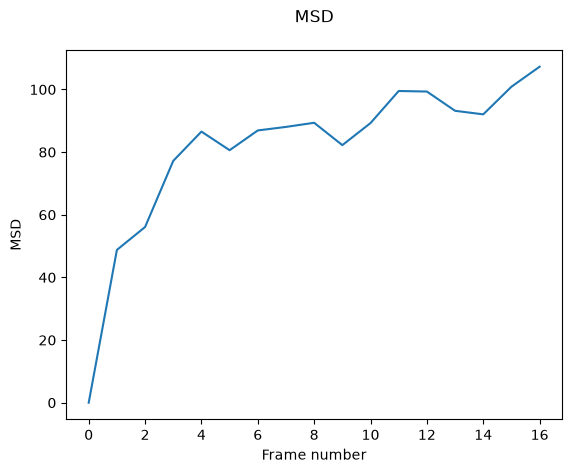

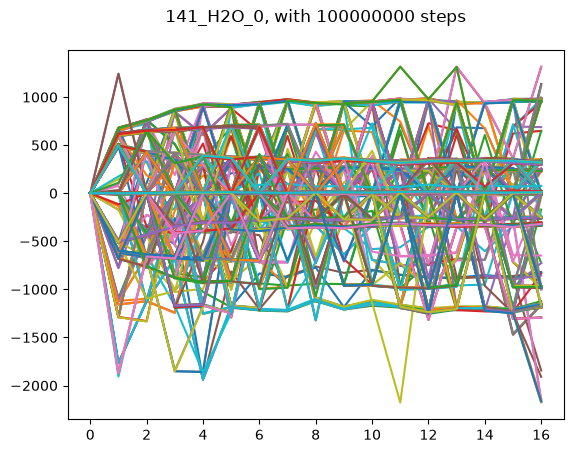

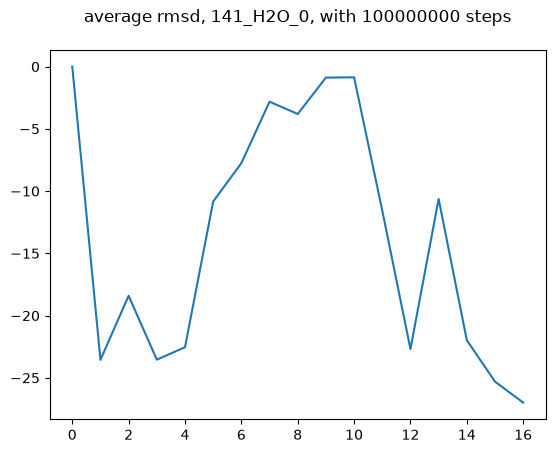

: 

In [ ]:
# relative mean squared displacement between hydrogen and oxygen neighbors 

for job in project.find_jobs({"compression": False}):
    print(job.id)
    if os.path.isfile(job.fn("trajectory.gsd")):
        data = gsd.hoomd.open(job.fn("trajectory.gsd"), 'r')
    else: 
        data = gsd.hoomd.open(job.fn("trajectory_temp.gsd"), 'r')

    plot_points = 100
    oxygen_neighbors = np.zeros(plot_points)

    num_frames = len(data)
    N = data[0].particles.N
    positions = np.zeros((num_frames, N, 3), dtype = float)
    
    for i, snap in enumerate(data): 
        box = freud.box.Box.from_box(snap.configuration.box)
        positions[i] = box.unwrap(snap.particles.position, snap.particles.image)
    
    points = data[0].particles.position

    msd_obj = freud.msd.MSD(box, mode = "direct")
    msd_computed = msd_obj.compute(positions)
    # take per particle msd of computed msd 
    pmsd = msd_computed.particle_msd
        
    aq = freud.locality.AABBQuery(box, points)

    query_ids = np.where(data[0].particles.typeid == 1)
    query_points = data[0].particles.position[query_ids]

    query_result = aq.query(query_points, dict(num_neighbors=4, exclude_ii=True))

    nlist = query_result.toNeighborList() 

    HO_pair_list = np.array([[i, j] for i, j in nlist if [snap.particles.typeid[i], snap.particles.typeid[j]] == [1, 0]])

    pair_relative_msd = pmsd[:, HO_pair_list[:, 0]] - pmsd[:, HO_pair_list[:, 1]]
    
    msd_computed.plot() 
    plt.show() 

    plt.plot(pair_relative_msd)
    plt.title(f"{job.sp.crystal_name}, with {job.sp.runtime} steps")
    plt.show()

    plt.plot(np.average(pair_relative_msd, axis = 1))
    plt.title(f"average rmsd, {job.sp.crystal_name}, with {job.sp.runtime} steps")
    
    


        